<a href="https://colab.research.google.com/github/Shadid123/Digital-Image-Processing/blob/main/Assignment%204/4.1_Spatial_Filtering_Correlation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Difference from OpenCV: 0.0


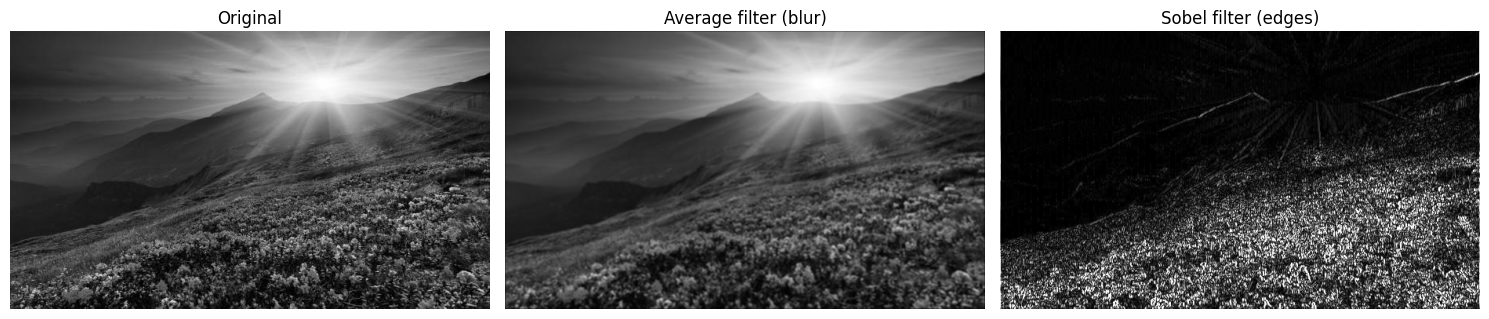

In [2]:
import numpy as np                  # tool for working with numbers and lists
import cv2                          # tool for reading the image
import matplotlib.pyplot as plt     # tool for drawing graphs

img = cv2.imread("/content/input.jpg", cv2.IMREAD_GRAYSCALE)   # open the picture in black and white

# Correlation function: slides the kernel over the picture
def correlation(image, kernel):
    k = kernel.shape[0]                              # kernel size (3 means 3x3)
    pad = k // 2                                     # how many extra border pixels we need (3x3 needs 1)
    M, N = image.shape                               # height and width of the picture
    padded = np.pad(image.astype(np.float64), pad, mode='constant')   # add a border of zeros so edge pixels can be filtered too
    out = np.zeros((M, N))                           # empty picture to store the result

    for a in range(k):                               # go through each row of the kernel
        for b in range(k):                           # go through each column of the kernel
            # multiply this one kernel number with the whole shifted picture, and add to the result
            # doing this for all kernel numbers = sliding the kernel over every pixel
            out += kernel[a, b] * padded[a:a+M, b:b+N]
    return out                                       # the filtered picture

# Kernel 1: average filter (blurs the picture)
# every pixel becomes the average of itself and its 8 neighbours
avg_kernel = np.ones((3, 3)) / 9

# Kernel 2: Sobel filter (finds vertical edges, where brightness changes left to right)
sobel_kernel = np.array([[-1, 0, 1],
                         [-2, 0, 2],
                         [-1, 0, 1]])

blur = correlation(img, avg_kernel)                  # apply the average filter
edge = correlation(img, sobel_kernel)                # apply the Sobel filter

# Check our function against OpenCV's built-in correlation (filter2D)
check = cv2.filter2D(img.astype(np.float64), cv2.CV_64F, avg_kernel, borderType=cv2.BORDER_CONSTANT)
print("Difference from OpenCV:", np.abs(blur - check).max())   # should be almost 0

# Show the results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)       # original picture
plt.title('Original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.clip(blur, 0, 255), cmap='gray', vmin=0, vmax=255)   # blurred picture (clip keeps values in 0..255)
plt.title('Average filter (blur)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(np.clip(np.abs(edge), 0, 255), cmap='gray', vmin=0, vmax=255)   # abs makes negative values positive so edges show
plt.title('Sobel filter (edges)')
plt.axis('off')

plt.tight_layout()
plt.show()